**Activity 3 — COVID-19 Dataset Exploration**

The dataset URL and Pakistan filter follow the supplied lab activity. This section uses daily changes in confirmed cases for the time-series and outlier analysis.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

covid_url = (
    "https://raw.githubusercontent.com/datasets/covid-19/master/"
    "data/time-series-19-covid-combined.csv"
)

covid = pd.read_csv(covid_url)
covid["Date"] = pd.to_datetime(covid["Date"])

pakistan = covid[covid["Country/Region"].eq("Pakistan")].copy()
pakistan = pakistan.sort_values("Date")

print(pakistan.head())

             Date Country/Region Province/State  Confirmed  Recovered  Deaths
168912 2020-01-22       Pakistan            NaN          0        0.0       0
168913 2020-01-23       Pakistan            NaN          0        0.0       0
168914 2020-01-24       Pakistan            NaN          0        0.0       0
168915 2020-01-25       Pakistan            NaN          0        0.0       0
168916 2020-01-26       Pakistan            NaN          0        0.0       0


In [3]:
daily = pakistan.groupby("Date", as_index=False).agg(
    Confirmed=("Confirmed", "sum"),
    Recovered=("Recovered", "sum"),
    Deaths=("Deaths", "sum")
)

daily["Daily_Cases"] = daily["Confirmed"].diff().fillna(daily["Confirmed"])
daily["Daily_Cases"] = daily["Daily_Cases"].clip(lower=0)

# Forward-fill any gaps, then use 0 for any values still missing.
daily = daily.ffill().fillna(0)

print("Missing values after cleaning:")
print(daily.isna().sum())

Missing values after cleaning:
Date           0
Confirmed      0
Recovered      0
Deaths         0
Daily_Cases    0
dtype: int64


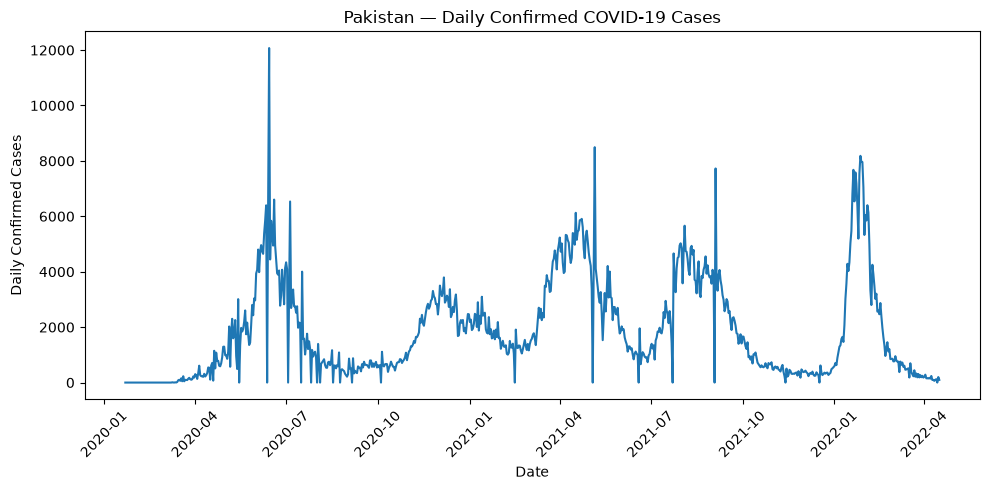

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(daily["Date"], daily["Daily_Cases"])
plt.xlabel("Date")
plt.ylabel("Daily Confirmed Cases")
plt.title("Pakistan — Daily Confirmed COVID-19 Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Day with highest reported daily confirmed cases:
Date           2020-06-14 00:00:00
Daily_Cases                12073.0
Name: 144, dtype: object


C:\Users\DELL\AppData\Local\Temp\ipykernel_17920\302441795.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(daily["Daily_Cases"], vert=False)


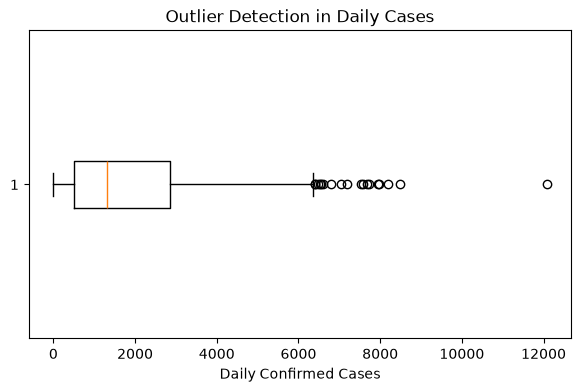

Number of IQR outlier days: 18


In [5]:
max_day = daily.loc[daily["Daily_Cases"].idxmax()]
print("Day with highest reported daily confirmed cases:")
print(max_day[["Date", "Daily_Cases"]])

plt.figure(figsize=(7, 4))
plt.boxplot(daily["Daily_Cases"], vert=False)
plt.xlabel("Daily Confirmed Cases")
plt.title("Outlier Detection in Daily Cases")
plt.show()

q1 = daily["Daily_Cases"].quantile(0.25)
q3 = daily["Daily_Cases"].quantile(0.75)
iqr = q3 - q1
outliers = daily[
    (daily["Daily_Cases"] < q1 - 1.5 * iqr) |
    (daily["Daily_Cases"] > q3 + 1.5 * iqr)
]
print("Number of IQR outlier days:", len(outliers))